In [1]:
from pathlib import Path
from modules.loading import load_files
from modules.preparation import prepare_oscar_nominations

BASE_DIR = Path.cwd()
OSCAR_FILE = BASE_DIR / 'data' / 'oscar_nominations.csv'
TITLES_FILE = BASE_DIR / 'data' / 'imdb_titles.tsv'
RATINGS_FILE = BASE_DIR / 'data' / 'imdb_ratings.tsv'

raw_nominations = load_files(OSCAR_FILE, ';')
nominations = prepare_oscar_nominations(raw_nominations)
ratings = load_files(RATINGS_FILE, '\t')

nominations_ratings = nominations.merge(
    ratings[['tconst', 'averageRating']],
    left_on='FilmId',
    right_on='tconst',
    validate='many_to_one'
).drop(columns=['tconst'])

# Оскар и зрительские оценки IMDb

## Вопрос 1
Как распределены рейтинги IMDb у победителей
в категории "Лучший фильм"?

In [2]:
from modules.calculating import calculate_rating_distribution

best_films = nominations_ratings.loc[
    (nominations_ratings['Winner'] == True) & (nominations_ratings['CanonicalCategory'] == 'BEST PICTURE'),
    ['Year', 'FilmId', 'Film', 'averageRating']
]

best_distribution = calculate_rating_distribution(best_films[['Year', 'averageRating']])

best_distribution

,rating_range,film_count,film_share_pct
0,1-2,0,0.0
1,2-3,0,0.0
2,3-4,0,0.0
3,4-5,0,0.0
4,5-6,0,0.0
5,6-7,0,0.0
6,7-8,14,38.9
7,8-9,20,55.6
8,9-10,2,5.6


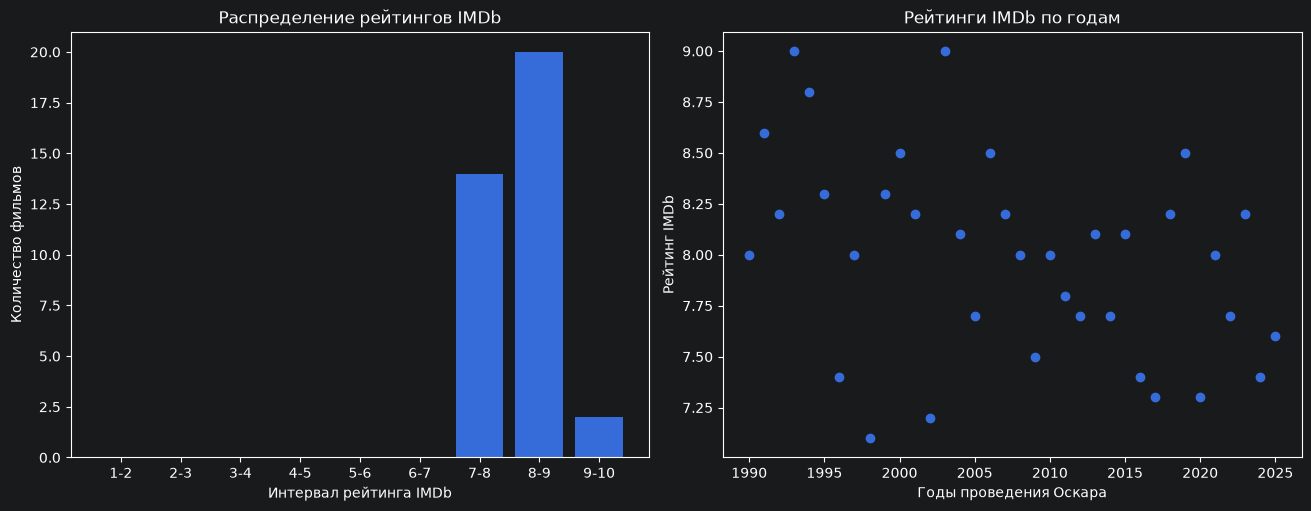

In [3]:
from modules.visualization import draw_rating_bar, draw_rating_scatter
import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(13, 5),
    layout='constrained'
)

draw_rating_bar(best_distribution, axes[0])
draw_rating_scatter(best_films[['Year', 'averageRating']], axes[1])

plt.show()


### Выводы
За период 1990–2025 годов победители в категории "Лучший фильм" получили преимущественно высокие оценки пользователей IMDb: 22 из 36 фильмов (61,1%) имеют рейтинг не ниже 8.

Рейтинг от 8 до 9 баллов получили 55,6% фильмов, от 9 до 10 баллов 5,6%. У остальных 38,9% рейтинг находится в диапазоне от 7 до 8 баллов. Фильмов с рейтингом ниже 7 в выборке нет.

#### Победители в категории "Лучший фильм" по годам

In [4]:
best_films

,Year,FilmId,Film,averageRating
74,1990,tt0099348,Dances With Wolves,8.0
182,1991,tt0102926,The Silence of the Lambs,8.6
287,1992,tt0105695,Unforgiven,8.2
394,1993,tt0108052,Schindler's List,9.0
499,1994,tt0109830,Forrest Gump,8.8
615,1995,tt0112573,Braveheart,8.3
727,1996,tt0116209,The English Patient,7.4
844,1997,tt0120338,Titanic,8.0
955,1998,tt0138097,Shakespeare in Love,7.1
1060,1999,tt0169547,American Beauty,8.3


## Вопрос 2
Как распределены рейтинги IMDb у фильмов, получивших наибольшее количество наград "Оскар" на каждой церемонии?

In [5]:
all_awarded_films = (
    nominations_ratings.loc[
        nominations_ratings['Winner'],
        ['FilmId', 'Year', 'Film', 'Winner', 'averageRating']
    ]
    .groupby(['FilmId', 'Year', 'Film', 'Winner', 'averageRating'], as_index=False)
    .agg(oscar_count=('Winner', 'count'))
    .query('oscar_count != 0')
    .sort_values('oscar_count', ascending=False)
)

top_awarded_films = all_awarded_films.drop_duplicates(subset=['Year']).drop(columns=['FilmId', 'Winner'])

top_awarded_distribution = calculate_rating_distribution(top_awarded_films[['Year', 'averageRating']])

top_awarded_distribution

,rating_range,film_count,film_share_pct
0,1-2,0,0.0
1,2-3,0,0.0
2,3-4,0,0.0
3,4-5,0,0.0
4,5-6,0,0.0
5,6-7,0,0.0
6,7-8,15,41.7
7,8-9,19,52.8
8,9-10,2,5.6


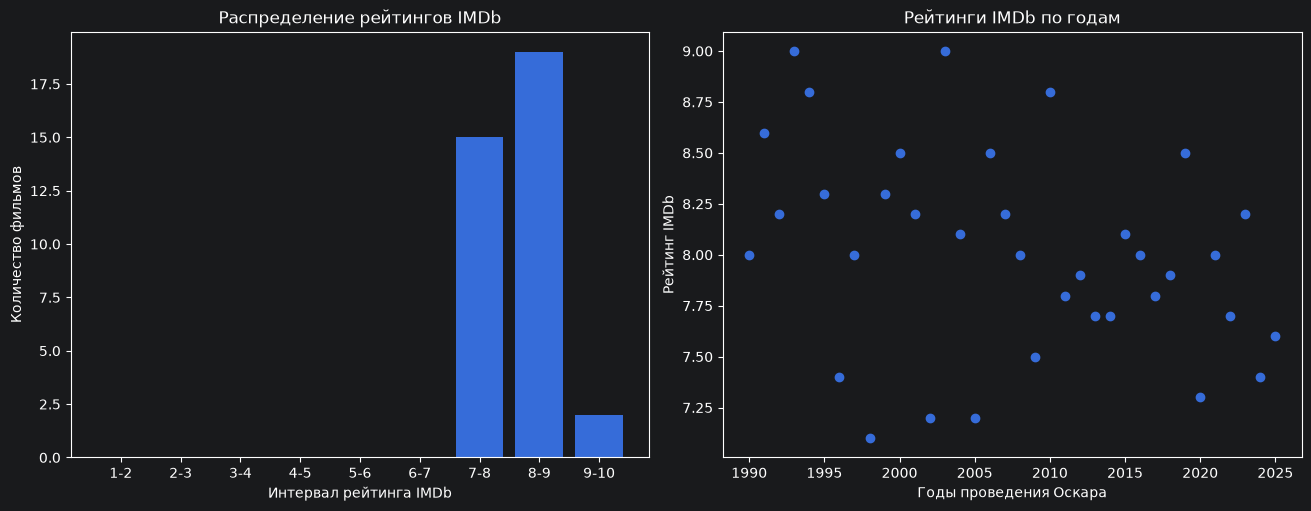

In [6]:
fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(13, 5),
    layout='constrained'
)

draw_rating_bar(top_awarded_distribution, axes[0])
draw_rating_scatter(top_awarded_films[['Year', 'averageRating']], axes[1])

plt.show()

### Выводы
За период 1990–2025 годов фильмы из выборки лидеров по количеству наград "Оскар" получили преимущественно высокие оценки пользователей IMDb: 21 из 36 фильмов (58,3%) имеет рейтинг не ниже 8.

Рейтинг от 8 до 9 баллов получили 52,8% фильмов, от 9 до 10 баллов 5,6%. У остальных 41,7% рейтинг находится в диапазоне от 7 до 8 баллов. Фильмов с рейтингом ниже 7 в выборке нет.

#### Лидеры по количеству наград "Оскар" по годам

In [7]:
top_awarded_films.sort_values('Year', ascending=True)

,Year,Film,averageRating,oscar_count
3,1990,Dances With Wolves,8.0,7
23,1991,The Silence of the Lambs,8.6,5
41,1992,Unforgiven,8.2,4
52,1993,Schindler's List,9.0,6
60,1994,Forrest Gump,8.8,6
73,1995,Braveheart,8.3,5
87,1996,The English Patient,7.4,8
107,1997,Titanic,8.0,9
121,1998,Shakespeare in Love,7.1,6
131,1999,American Beauty,8.3,5


## Вопрос 3
Как часто "Лучший фильм" одновременно получает максимум наград на церемонии?

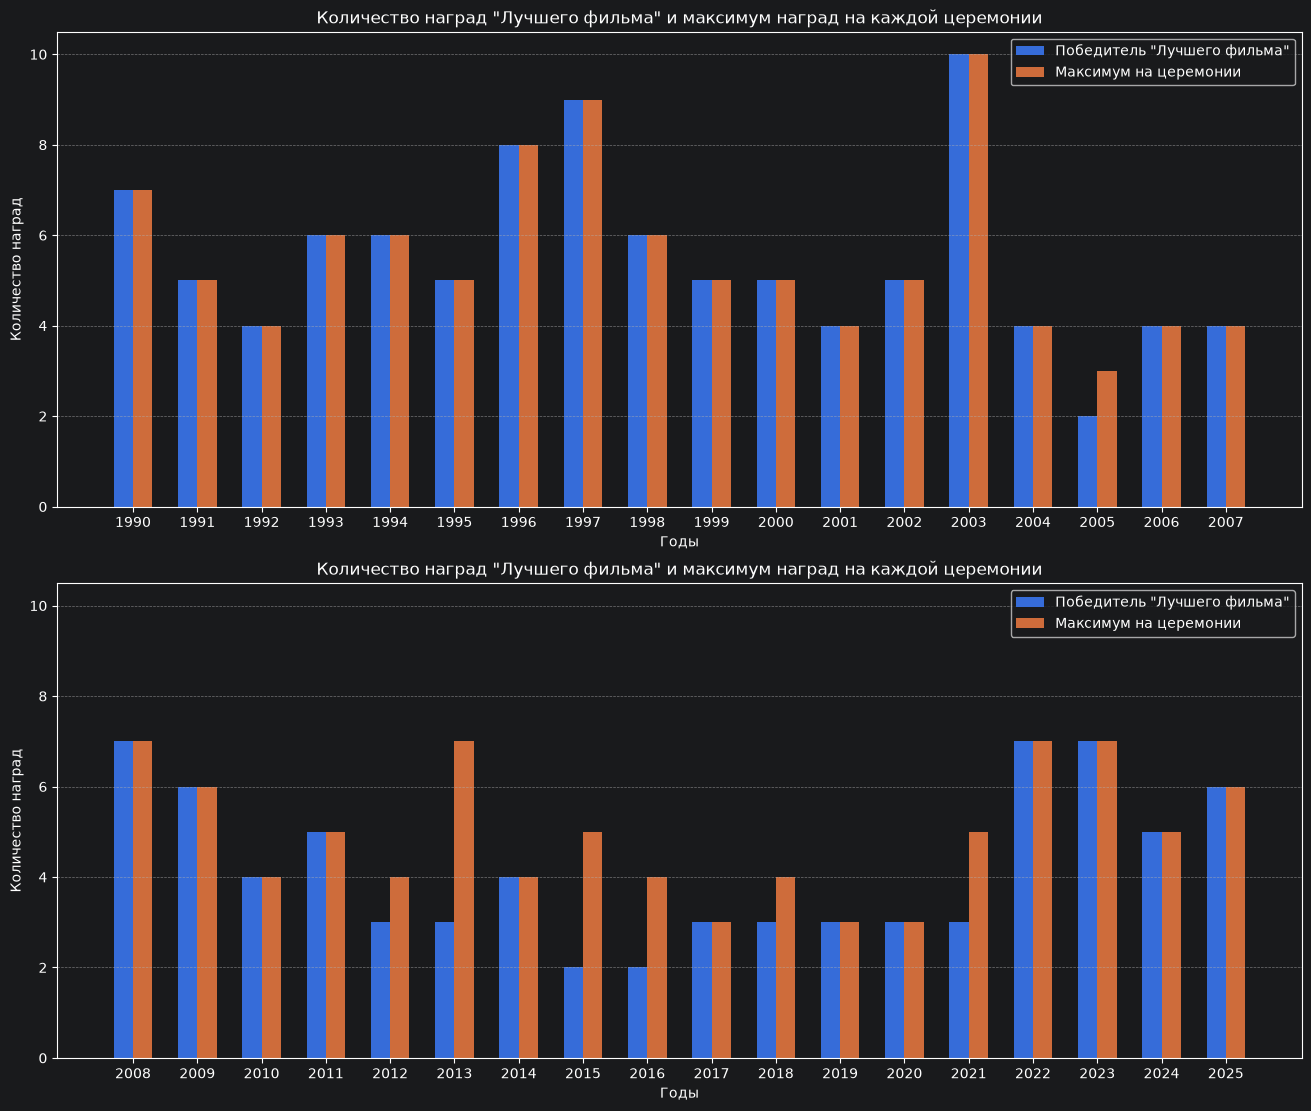

In [8]:
from modules.visualization import draw_double_bar

films_oscar_count = (
    best_films.merge(
        all_awarded_films[['FilmId', 'oscar_count']],
        on='FilmId',
        validate='many_to_one'
    )
    .drop(columns=['Film', 'FilmId', 'averageRating'])
    .merge(
        top_awarded_films[['Year', 'oscar_count']],
        on='Year',
        validate='many_to_one',
        suffixes=('_best_picture', '_max')
    )
)

fig, axes = plt.subplots(
    nrows=2, ncols=1,
    figsize=(13, 11),
    layout='constrained',
    sharey=True
)

draw_double_bar(
    films_oscar_count['Year'].iloc[:18],
    films_oscar_count['oscar_count_best_picture'].iloc[:18],
    films_oscar_count['oscar_count_max'].iloc[:18],
    axes[0]
)

draw_double_bar(
    films_oscar_count['Year'].iloc[18:],
    films_oscar_count['oscar_count_best_picture'].iloc[18:],
    films_oscar_count['oscar_count_max'].iloc[18:],
    axes[1]
)

plt.show()

### Доля церемоний, на которых "Лучший фильм" получил максимум наград

In [15]:
films_oscar_count['is_top_awarded'] = films_oscar_count['oscar_count_best_picture'] == films_oscar_count['oscar_count_max']
best_film_share_pct = films_oscar_count[films_oscar_count['is_top_awarded']].count()

print(round((best_film_share_pct['is_top_awarded'] / 36) * 100, 2), '%')

80.56 %


### Выводы
За период 1990–2025 годов победитель в категории "Лучший фильм" получил максимальное число наград на 29 из 36 церемоний (80,56%).

Таким образом, можно сказать, что победители в категории "Лучший фильм" зачастую также лидируют по общему количеству наград, хотя эти достижения совпадают не всегда.